# Makale Yeniden Üretimi – Bölüm 9: Karar Ağacı
**Ahmet Nail Arslan · 20269348010**

**Makale:** Cortez, P. ve Silva, A. (2008). *Using Data Mining to Predict Secondary School Student Performance.* FUBUTEC 2008.

**Bölümle bağlantısı:** Makale karar ağacını bir taban çizgisi ve rastgele ormanla kıyaslar, sonra ağaçları kural olarak okur.

**Sınanan iddialar**
1. Önceki notlar bilindikçe tahmin iyileşir (A > B > C).
2. Matematik sınıflamasında A'da en iyisi son notu aynen kullanmaktır.
3. Kalan durumlarda ağaç tabanlı yöntemler öndedir.
4. Ağaçların kökünde notlar vardır, az öznitelik kullanılır.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
from IPython.display import Image, display
import agac, calistir, calistir_697, figurler, kararsizlik, veri697
pd.set_option("display.max_colwidth", 90)

YENIDEN_CALISTIR = False   # True: bütün deneyleri baştan çalıştırır (32 çekirdekle ~6 dk)
if YENIDEN_CALISTIR:
    calistir.calistir(); calistir_697.calistir()

## 1. Veri
İki ders, 32 öznitelik. Hedef yıl sonu notu G3 (0–20). Görevler: geçti/kaldı, 5 düzey, notun kendisi.

In [2]:
for d in agac.DERSLER:
    v = agac.oku(d)
    print(d, v.shape, "| geçen oranı:", round((v.G3 >= 10).mean(), 3), "| G2-G3 korelasyonu:", round(v.G2.corr(v.G3), 3))

Mat (395, 33) | geçen oranı: 0.671 | G2-G3 korelasyonu: 0.905
Por (649, 33) | geçen oranı: 0.846 | G2-G3 korelasyonu: 0.919


## 2. Karar ağacı nasıl kuruluyor?
Her düğümde **tüm öznitelikler ve tüm kesimler** denenir, safsızlığı en çok azaltan seçilir (Gini / kareler toplamı).
Kategorik öznitelikte kategorilerin **alt kümeleri** denenir. Sonra $R(T)+\alpha|T|$ en küçük olacak biçimde budanır; $\alpha$ = 0,01 × kök riski.

Budamanın etkisi (Portekizce, geçti/kaldı, A):

In [3]:
X, y, adlar, kat = agac.hazirla("Por", "Bin", "A")
for cp in (0, 0.01, 0.05):
    m = agac.Agac(True, kat, cp=cp).fit(X, y)
    yaprak, kul = m.ozet(adlar)
    print(f"cp={cp:<5} yaprak={yaprak:>2}  eğitim doğruluğu={100*(m.predict(X)==y).mean():.1f}  kullanılan: {kul}")

cp=0     yaprak= 7  eğitim doğruluğu=95.2  kullanılan: ['G2', 'G1', 'Mjob', 'school', 'absences']
cp=0.01  yaprak= 5  eğitim doğruluğu=94.9  kullanılan: ['G2', 'G1', 'Mjob']
cp=0.05  yaprak= 2  eğitim doğruluğu=93.7  kullanılan: ['G2']


In [4]:
m = agac.Agac(True, kat).fit(X, y)
print(m.yaz(adlar, ["Kaldı", "Geçti"]))

G2 < 8.5 ?
   evet: → Kaldı  (n=73)
   hayır: G1 < 9.5 ?
      evet: G2 < 9.5 ?
         evet: Mjob ∈ {other, teacher} ?
            evet: → Geçti  (n=23)
            hayır: → Kaldı  (n=16)
         hayır: → Geçti  (n=50)
      hayır: → Geçti  (n=487)


Makaledeki 1. ve 2. kural aynen çıktı: *G1 < 10 ve G2 = 9 iken* anne mesleği öğretmen ya da "other" ise **geçti**, değilse **kaldı**.

## 3. Tek tekrarı canlı çalıştıralım

In [5]:
pd.DataFrame(agac.tek_tekrar("Mat", "Bin", "A", tohum=0))[["yontem", "deger"]].round(1)

,yontem,deger
0,NV,91.9
1,DT,90.1
2,RF,90.9


## 4. Tablo 3: Geçti/kaldı (PCC, %)
**M** = makale, **YÜ** = yeniden üretim (20 tekrar ortalaması ± %95 güven aralığı).

In [6]:
figurler.tablo("Bin")

NV M      NV YÜ  DT M      DT YÜ  RF M      RF YÜ
ders kurulum                                                   
Mat  A        91.9  91.9 ±0.0  90.7  90.4 ±0.3  91.2  90.9 ±0.2
     B        83.8  83.8 ±0.0  83.1  83.3 ±0.6  83.0  83.3 ±0.4
     C        67.1  67.1 ±0.0  65.3  66.3 ±0.7  70.5  71.1 ±0.4
Por  A        89.7  89.7 ±0.0  93.0  92.8 ±0.2  92.6  92.6 ±0.1
     B        87.5  87.5 ±0.0  88.4  88.5 ±0.4  90.1  90.2 ±0.2
     C        84.6  84.6 ±0.0  84.4  84.1 ±0.4  85.0  85.0 ±0.2

## 5. Tablo 4: 5 düzey (PCC, %)

In [7]:
figurler.tablo("5L")

NV M      NV YÜ  DT M      DT YÜ  RF M      RF YÜ
ders kurulum                                                   
Mat  A        78.5  78.5 ±0.0  76.7  76.8 ±0.3  72.4  72.1 ±0.6
     B        60.5  60.5 ±0.0  57.5  57.6 ±0.6  52.7  52.9 ±0.7
     C        32.9  32.9 ±0.0  31.5  31.4 ±0.9  33.5  33.9 ±0.6
Por  A        72.9  72.9 ±0.0  76.1  76.7 ±0.1  73.5  73.3 ±0.3
     B        58.7  58.7 ±0.0  62.9  62.8 ±0.2  55.3  55.6 ±0.4
     C        31.0  31.0 ±0.0  32.8  32.8 ±0.8  36.7  36.9 ±0.4

## 6. Tablo 5: Regresyon (RMSE)

In [8]:
figurler.tablo("Reg")

NV M       NV YÜ  DT M       DT YÜ  RF M       RF YÜ
ders kurulum                                                      
Mat  A        2.01  2.01 ±0.00  1.94  1.97 ±0.03  1.75  1.77 ±0.01
     B        2.80  2.80 ±0.00  2.67  2.68 ±0.04  2.46  2.44 ±0.01
     C        4.59  4.59 ±0.00  4.46  4.43 ±0.04  3.90  3.87 ±0.01
Por  A        1.32  1.32 ±0.00  1.46  1.47 ±0.02  1.32  1.33 ±0.01
     B        1.89  1.89 ±0.00  1.78  1.73 ±0.02  1.79  1.78 ±0.00
     C        3.23  3.23 ±0.00  2.93  2.92 ±0.02  2.67  2.66 ±0.01

In [9]:
ort, ga = figurler.ozet()
fark = (ort - figurler.MAKALE).abs()
print("En büyük fark, sınıflama (puan):", fark.drop("Reg").max().round(2).to_dict())
print("En büyük fark, regresyon (RMSE):", fark.loc["Reg"].max().round(3).to_dict())

En büyük fark, sınıflama (puan): {'NV': 0.03, 'DT': 1.03, 'RF': 0.64}
En büyük fark, regresyon (RMSE): {'NV': 0.004, 'DT': 0.046, 'RF': 0.03}


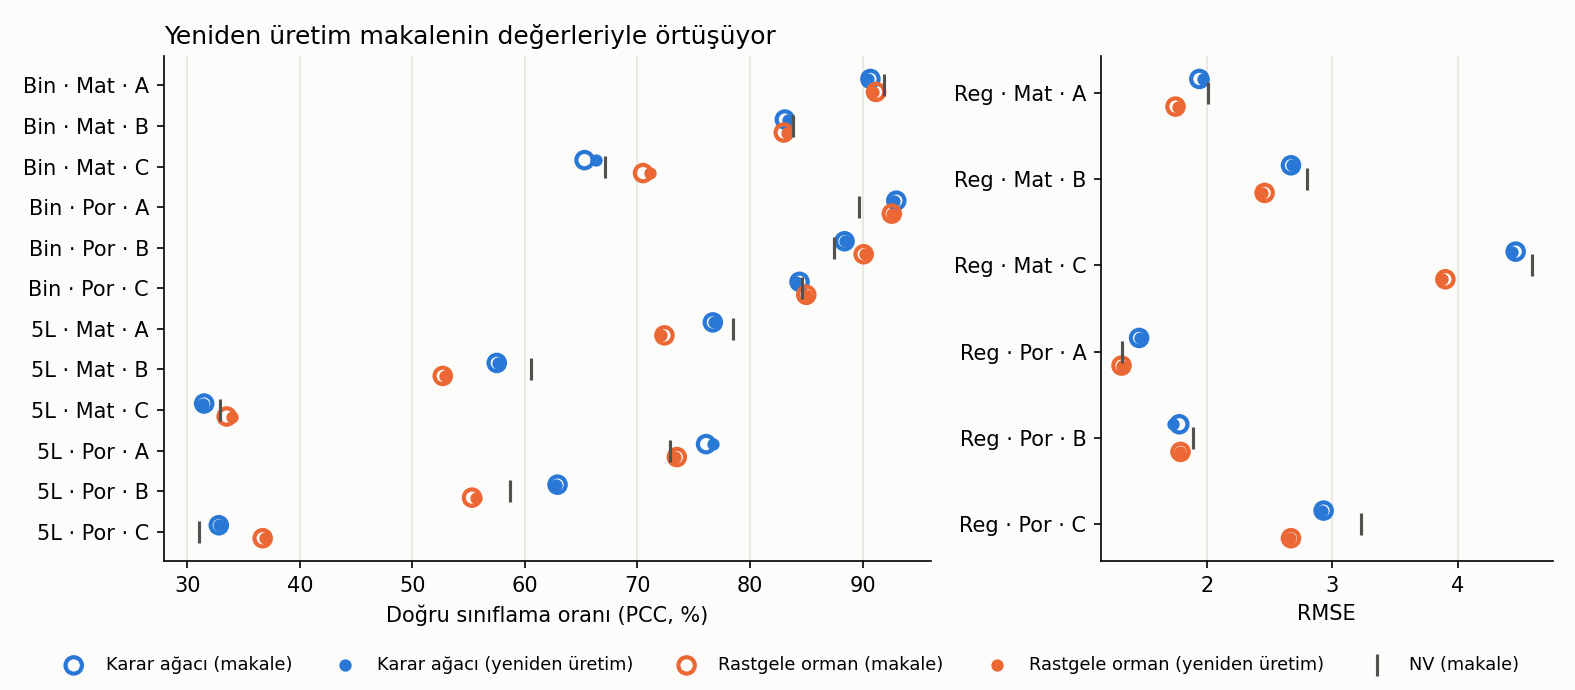

In [10]:
figurler.sekil1(); display(Image("sekiller/sekil1_karsilastirma.png"))

NV rastgelelik içermez ve 18/18 hücrede birebir. DT ve RF küçük farklarla makaleyi izliyor.

## 7. İddialar

In [11]:
# İddia 1: A > B > C  (RMSE'de küçük olan iyi)
def sirali(s, g):
    a, b, c = s["A"], s["B"], s["C"]
    return (a < b < c) if g == "Reg" else (a > b > c)
print("İddia 1:", sum(sirali(ort.loc[(g, d), m], g) for g in agac.GOREVLER for d in agac.DERSLER for m in ort), "/ 18")

# İddia 2 ve 3: satır başına kazanan
k = pd.DataFrame({"makale": figurler.kazanan(figurler.MAKALE), "yeniden üretim": figurler.kazanan(ort)})
k["aynı"] = k.iloc[:, 0] == k.iloc[:, 1]
print("Kazanan aynı:", k["aynı"].sum(), "/ 18"); k

İddia 1: 18 / 18
Kazanan aynı: 17 / 18


makale yeniden üretim   aynı
gorev ders kurulum                             
Bin   Mat  A           NV             NV   True
           B           NV             NV   True
           C           RF             RF   True
      Por  A           DT             DT   True
           B           RF             RF   True
           C           RF             RF   True
5L    Mat  A           NV             NV   True
           B           NV             NV   True
           C           RF             RF   True
      Por  A           DT             DT   True
           B           DT             DT   True
           C           RF             RF   True
Reg   Mat  A           RF             RF   True
           B           RF             RF   True
           C           RF             RF   True
      Por  A        NV/RF             NV  False
           B           DT             DT   True
           C           RF             RF   True

Tek farklı satır Por A (Reg): makalede NV ve RF 1,32 ile eşit, bizde RF 1,33.
NN ve SVM çalıştırılmadığı için 3. iddianın onlarla ilgili kısmı sınanmadı.

## 8. İddia 4: Şekil 4'teki ağaçlar

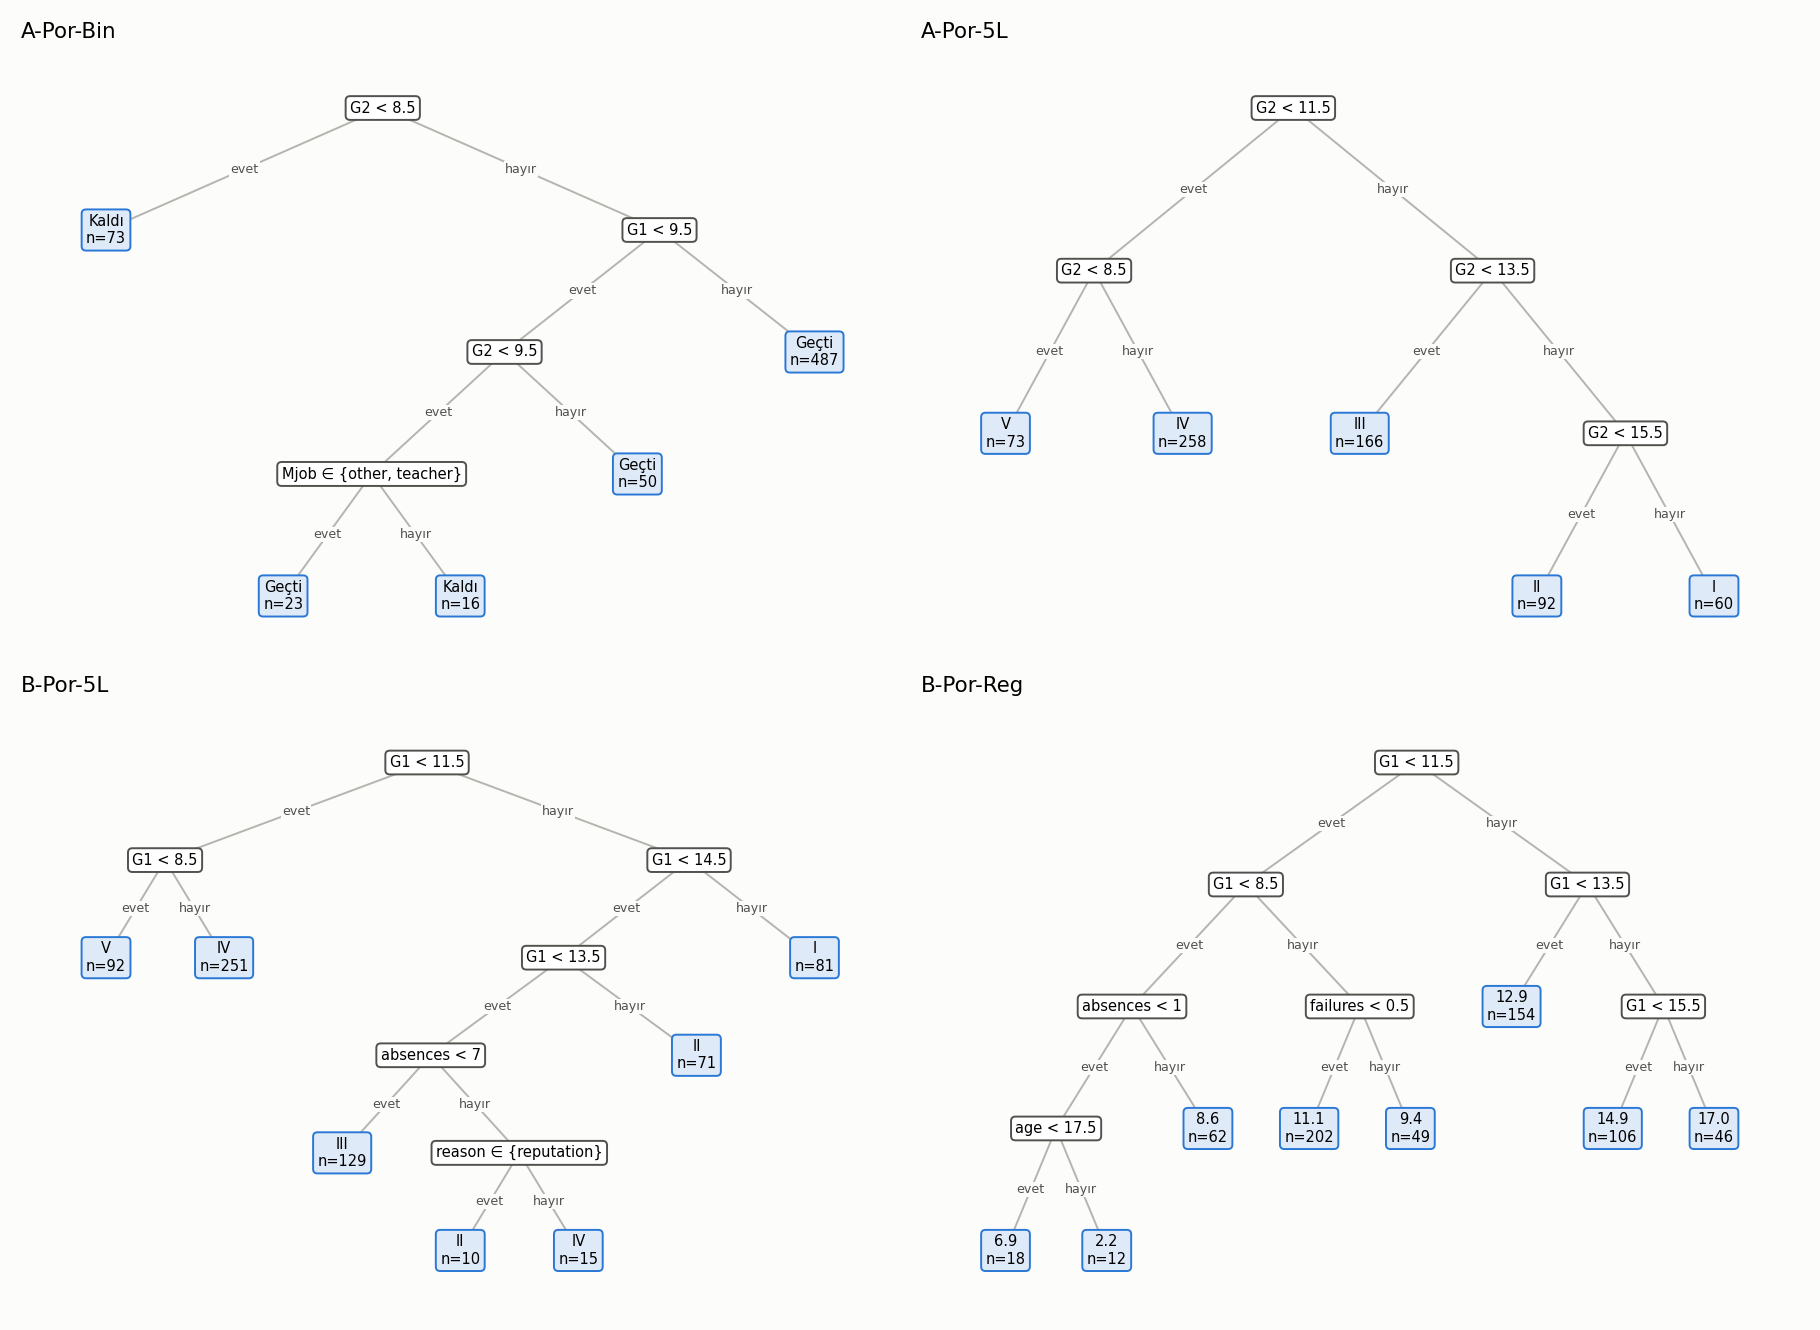

In [12]:
figurler.sekil2(); display(Image("sekiller/sekil2_agaclar.png"))

In [13]:
for d, g, kur in figurler.AGACLAR:
    m, adlar, s = figurler.agac_kur(d, g, kur)
    print(f"{kur}-{d}-{g}: yaprak ve öznitelikler", m.ozet(adlar))

A-Por-Bin: yaprak ve öznitelikler (5, ['G2', 'G1', 'Mjob'])
A-Por-5L: yaprak ve öznitelikler (5, ['G2'])
B-Por-5L: yaprak ve öznitelikler (7, ['G1', 'absences', 'reason'])
B-Por-Reg: yaprak ve öznitelikler (8, ['G1', 'absences', 'failures', 'age'])


- **A-Por-Bin:** aynı yapı. Şekilde kök `G2<8`, ama makalenin kendi kuralı (G2 = 9) bizdeki `G2 < 9` ile uyumlu.
- **B-Por-5L:** tamamen aynı.
- **A-Por-5L:** G2 bölünmeleri aynı; `goout` bölünmesi bizde yok.
- **B-Por-Reg:** üst bölünmeler aynı, alt dallar farklı.

Farkın hangi ayar ya da sürümden geldiği bilinmiyor. Ama bu tür bir fark ne kadar önemli?

## 9. Sınır: ağaç kararsızlığı (Molnar, Bölüm 9)
Önce canlı: aynı verinin üç bootstrap örneğinde A-Por-Bin ağacı.

In [14]:
import numpy as np
X, y, adlar, kat = agac.hazirla("Por", "Bin", "A")
rng = np.random.default_rng(1)
for b in range(3):
    i = rng.integers(0, len(y), len(y))
    print(f"--- örnek {b+1}")
    print(agac.Agac(True, kat).fit(X[i], y[i]).yaz(adlar, ["Kaldı", "Geçti"]))

--- örnek 1
G2 < 8.5 ?
   evet: famsize = GT3 ?
      evet: → Kaldı  (n=55)
      hayır: absences < 3.5 ?
         evet: → Kaldı  (n=12)
         hayır: → Geçti  (n=8)
   hayır: G1 < 8.5 ?
      evet: Mjob ∈ {at_home, services} ?
         evet: → Kaldı  (n=16)
         hayır: → Geçti  (n=22)
      hayır: G2 < 9.5 ?
         evet: health < 4.5 ?
            evet: → Geçti  (n=27)
            hayır: Fjob ∈ {other, teacher} ?
               evet: → Kaldı  (n=11)
               hayır: → Geçti  (n=9)
         hayır: → Geçti  (n=489)
--- örnek 2
G2 < 8.5 ?
   evet: G1 < 8.5 ?
      evet: → Kaldı  (n=64)
      hayır: → Geçti  (n=16)
   hayır: G1 < 9.5 ?
      evet: absences < 7 ?
         evet: → Geçti  (n=55)
         hayır: age < 17.5 ?
            evet: → Kaldı  (n=14)
            hayır: → Geçti  (n=7)
      hayır: → Geçti  (n=493)
--- örnek 3
G2 < 8.5 ?
   evet: famrel < 2.5 ?
      evet: G1 < 7.5 ?
         evet: → Kaldı  (n=11)
         hayır: → Geçti  (n=9)
      hayır: → Kaldı  (n=62)


Dört ağaç × 100 bootstrap. Yüzde: tüm veriyle kurulan ağacın bölünmesi bootstrap ağacında aynı yerde ve aynı eşikle mi?

In [15]:
kr = figurler.kararsizlik_verisi()
kararsizlik.ozet(kr).round(0).T

,0,1,2,3
ağaç,A-Por-Bin,A-Por-5L,B-Por-5L,B-Por-Reg
kök,G2 < 8.5,G2 < 11.5,G1 < 11.5,G1 < 11.5
kök %,81.0,100.0,82.0,80.0
2. düzey evet,yaprak,G2 < 8.5,G1 < 8.5,G1 < 8.5
evet %,67.0,92.0,95.0,84.0
2. düzey hayır,G1 < 9.5,G2 < 13.5,G1 < 14.5,G1 < 13.5
hayır %,35.0,81.0,45.0,63.0
üçü birden %,28.0,75.0,40.0,46.0
kök özniteliği aynı %,88.0,100.0,100.0,100.0
"yaprak (tam / bootstrap medyan, min–maks)","5 / 6, 3–13","5 / 8, 5–15","7 / 12, 5–22","8 / 8, 6–12"


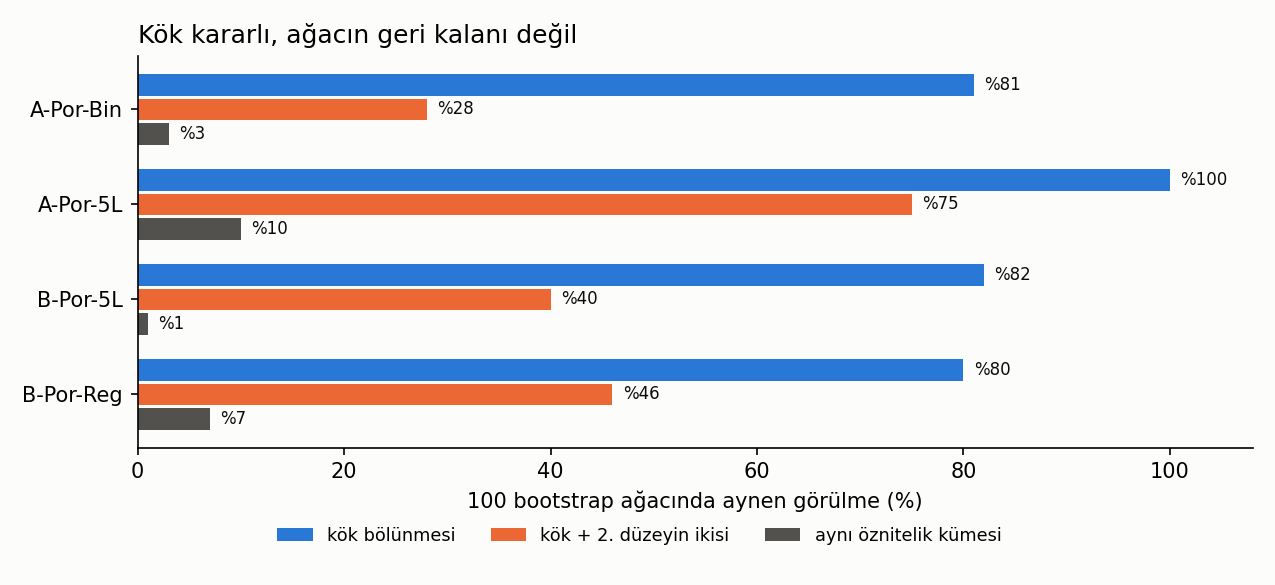

In [16]:
figurler.sekil4(); display(Image("sekiller/sekil4_kararsizlik.png"))

In [17]:
os_ = kararsizlik.oznitelik_sikligi(kr)
os_.loc[["G1", "G2", "Mjob", "absences", "failures", "reason", "goout"]].round(0)   # kullanılma yüzdesi

agac,A-Por-Bin,A-Por-5L,B-Por-5L,B-Por-Reg
o,,,,
G1,79.0,36.0,100.0,100.0
G2,100.0,100.0,0.0,0.0
Mjob,43.0,36.0,63.0,9.0
absences,30.0,26.0,68.0,88.0
failures,11.0,1.0,6.0,59.0
reason,10.0,14.0,38.0,20.0
goout,13.0,10.0,22.0,18.0


- Kök kararlı (%80–100), alt dallar değil.
- `goout` A-Por-5L ağaçlarının %10'unda: bir öğrencilik kazanca dayanan bölünme **bulgu gibi yorumlanmamalı**.
- Makalede neden çıktığı bilinmiyor; aynı veri ve ayarlarla ağaç deterministik olduğundan bootstrap bunu açıklamaz.

## 10. Kendi verim: okul terki (UCI 697)
4.424 öğrenci. A = hepsi, B = 2. dönem yok, C = dönem bilgisi yok. NV = tek dönemin geçilen/alınan ders oranı.

In [18]:
d = veri697.oku()
print(d.shape, d.Target.value_counts(normalize=True).round(3).to_dict())
m, adlar, s = veri697.agac_kur("Bin", "A")
print(m.yaz(adlar, s))

(4424, 37) {'Graduate': 0.499, 'Dropout': 0.321, 'Enrolled': 0.179}


2. dönem approved < 3.5 ?
   evet: 2. dönem approved < 1.5 ?
      evet: Course ∈ {171} ?
         evet: Tuition fees up to date < 0.5 ?
            evet: → Dropout  (n=25)
            hayır: → Diğer  (n=155)
         hayır: → Dropout  (n=804)
      hayır: Tuition fees up to date < 0.5 ?
         evet: → Dropout  (n=89)
         hayır: Age at enrollment < 22.5 ?
            evet: → Diğer  (n=275)
            hayır: → Dropout  (n=119)
   hayır: Tuition fees up to date < 0.5 ?
      evet: GDP < 1.905 ?
         evet: → Dropout  (n=98)
         hayır: → Diğer  (n=55)
      hayır: → Diğer  (n=2804)


In [19]:
figurler.tablo697()

NV         DT         RF en iyi
gorev kurulum                                        
3S    A        63.7 ±0.0  73.5 ±0.2  77.8 ±0.1     RF
      B        60.0 ±0.0  70.1 ±0.1  74.4 ±0.1     RF
      C        49.9 ±0.0  62.0 ±0.1  64.3 ±0.1     RF
Bin   A        83.5 ±0.0  85.7 ±0.1  87.7 ±0.1     RF
      B        80.6 ±0.0  83.8 ±0.1  85.6 ±0.1     RF
      C        67.9 ±0.0  77.2 ±0.1  78.6 ±0.1     RF

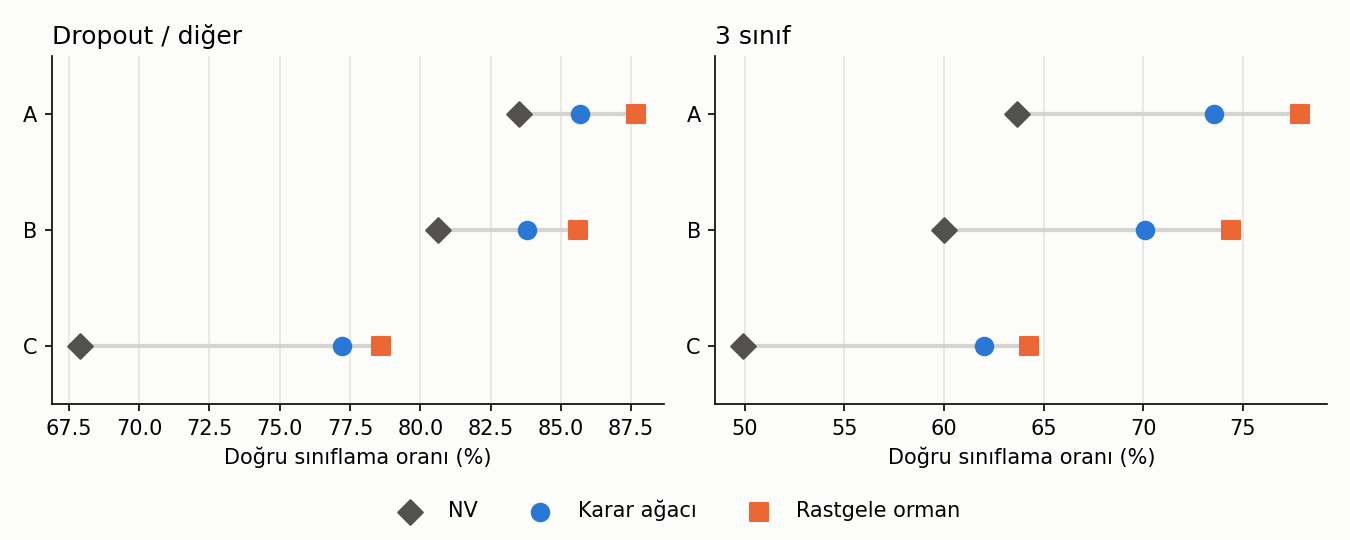

In [20]:
figurler.sekil3(); display(Image("sekiller/sekil3_697.png"))

In [21]:
figurler.iddialar697()

,iddia,bulgu,sonuç
0,1: A > B > C,6/6 (görev × yöntem),✔
1,2: A'da en iyisi NV,0/2 görev,✘
2,3: Ağaç tabanlılar önde (NN/SVM yok),6/6 satırda DT ya da RF birinci,✔
3,"4: Kökte notlar, az öznitelik","A/B ağaçlarında kök: ['1. dönem approved', '2. dönem approved']; öznitelik sayısı 3–5",✔


**İddia 2 tutmadı.** Makalede G2 ile G3 aynı ölçekte; burada tek dönemin başarısı hedefi ayırmaya yetmiyor.

**Veri kusuru denetimi:** 171 numaralı bölümde 180 öğrencinin bütün ders sütunları 0, ama 75'i mezun; NV onları Dropout sayar.
Bu öğrenciler hariç:

In [22]:
figurler.tablo697("deger_kayitli")

NV         DT         RF en iyi
gorev kurulum                                        
3S    A        64.5 ±0.0  74.8 ±0.2  78.8 ±0.1     RF
      B        60.7 ±0.0  71.3 ±0.1  75.2 ±0.1     RF
      C        50.3 ±0.0  62.4 ±0.1  64.7 ±0.1     RF
Bin   A        85.2 ±0.0  86.7 ±0.1  88.5 ±0.1     RF
      B        82.2 ±0.0  84.5 ±0.1  86.3 ±0.0     RF
      C        68.3 ±0.0  77.6 ±0.1  79.1 ±0.1     RF

Sıralama değişmiyor.

### Sızıntı ölçümü: hiç sınava girmeyen öğrenciler
"Alınan ders = 0" satırlarının hepsi 180 kayıtsız öğrencidir (onlar hariç 0 satır). Asıl sızıntı: o dönem hiç değerlendirmeye girmemek.

In [23]:
veri697.sifir_dagilimi()

,dönem,koşul,satır,Dropout,Enrolled,Graduate
0,1.,alınan ders = 0,0,0,0,0
1,1.,değerlendirme = 0,169,169,0,0
2,1.,geçilen ders = 0,538,493,43,2
3,2.,alınan ders = 0,0,0,0,0
4,2.,değerlendirme = 0,221,220,1,0
5,2.,geçilen ders = 0,690,650,40,0


A 2. dönemin, B 1. dönemin satırları çıkarılarak yeniden çalıştırıldı (*kayit* = 180 öğrenci yok; *sinav* = ayrıca değerlendirme = 0 yok; *gecen* = ayrıca geçilen ders = 0 yok). Aynı satırlarda C karşılaştırma için.

In [24]:
figurler.tablo_sizinti()

,görev,kurulum,çıkarılan,n,çoğunluk,NV,DT,RF
0,Bin,A,eski,4424,67.9,83.5 ±0.0,85.7 ±0.1,87.7 ±0.1
1,Bin,A,kayit,4244,68.3,85.2 ±0.0,86.6 ±0.0,88.5 ±0.1
2,Bin,A,sinav,4023,72.1,84.5 ±0.0,85.9 ±0.1,87.9 ±0.1
3,Bin,A,gecen,3554,80.5,83.5 ±0.0,85.5 ±0.1,87.1 ±0.1
4,Bin,B,eski,4424,67.9,80.6 ±0.0,83.8 ±0.1,85.6 ±0.1
5,Bin,B,kayit,4244,68.3,82.2 ±0.0,84.6 ±0.1,86.4 ±0.1
6,Bin,B,sinav,4075,71.2,81.5 ±0.0,84.0 ±0.1,85.8 ±0.1
7,Bin,B,gecen,3706,77.0,80.9 ±0.0,83.4 ±0.1,85.4 ±0.1
8,Bin,C,eski,4424,67.9,67.9 ±0.0,77.2 ±0.1,78.6 ±0.1
9,Bin,C,sinav,4023,72.1,72.1 ±0.0,79.6 ±0.1,81.2 ±0.1


In [25]:
veri697.kok_tablosu()

,görev,kurulum,çıkarılan,n,kök,öznitelikler
0,Bin,A,eski,4424,2. dönem approved < 3.5,"2. dönem approved, Tuition fees up to date, Course, GDP, Age at enrollment"
1,Bin,A,kayit,4244,2. dönem approved < 2.5,"2. dönem approved, Tuition fees up to date"
2,Bin,A,sinav,4023,2. dönem approved < 2.5,"2. dönem approved, Tuition fees up to date"
3,Bin,A,gecen,3554,2. dönem approved < 3.5,"2. dönem approved, Tuition fees up to date, Age at enrollment, GDP, Father's occupatio..."
4,Bin,B,eski,4424,1. dönem approved < 3.5,"1. dönem approved, Tuition fees up to date, Course, Application mode, 1. dönem grade"
5,Bin,B,kayit,4244,1. dönem approved < 3.5,"1. dönem approved, 1. dönem grade, Tuition fees up to date, Course"
6,Bin,B,sinav,4075,1. dönem approved < 3.5,"1. dönem approved, Tuition fees up to date, 1. dönem grade, Course"
7,Bin,B,gecen,3706,Tuition fees up to date < 0.5,"Tuition fees up to date, GDP, 1. dönem approved, Course, Age at enrollment, Father's o..."
8,3S,A,eski,4424,2. dönem approved < 3.5,"2. dönem approved, Tuition fees up to date, Age at enrollment, Course, 1. dönem approved"
9,3S,A,kayit,4244,2. dönem approved < 3.5,"2. dönem approved, Tuition fees up to date, Age at enrollment, Course, 1. dönem approved"


221 öğrencinin 220'si bırakmış: bu satırlar hedefi fiilen gösteriyor. Ama çıkarılınca sıralama ve iddia 2'nin ✘ sonucu değişmiyor; kök özniteliği 12'de 11 aynı.
A'nın C'ye üstünlüğünün bir kısmı bu satırlardan geliyor (RF, ikili: 9,1 → 6,7 puan), büyük kısmı gelmiyor.

**Kategori sıralamasında sızıntı yok:** `_sirala` (agac.py:136) yalnızca düğümdeki eğitim örneklerini görür. Sınama:

In [26]:
import numpy as np
X, y, adlar, kat = veri697.hazirla("3S", "A")
f = np.random.default_rng(0).permutation(len(y)) % 10
tr, te = f != 0, f == 0
y2 = y.copy(); y2[te] = (y2[te] + 1) % 3                         # test etiketlerini boz
p = agac.Agac(True, kat).fit(X[tr], y[tr]).predict(X[te])
q = agac.Agac(True, kat).fit(X[tr], y2[tr]).predict(X[te])
print("bozulan test etiketi:", (y != y2).sum(), "| değişen tahmin:", (p != q).sum())

bozulan test etiketi: 443 | değişen tahmin: 0


## 11. Sonuç
- **Kıyaslama:** DT 18 satırın 4'ünde birinci (RF 9, NV 5). Matematik sınıflamasında A ve B'de tek satırlık NV ağacı geçiyor.
- **Yeni veri:** NV üstünlüğü kayboluyor; ağaç NV'yi geçiyor ama altı satırın hepsinde RF'nin gerisinde.
- **Kararsızlık:** kök güvenilir, alt dallardaki ilgi çekici kurallar değil.